# Obtaining raw data

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


Create folder for the dataset

In [ ]:
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "experiments",
    "figures"
]

# Check if any of the folders are missing
missing_folders = [f for f in folders if not (PROJECT_DIR / f).exists()]

if missing_folders:
    for folder in missing_folders:
        (PROJECT_DIR / folder).mkdir(
            parents=True,
            exist_ok=True
        )
    print("Created folder:", missing_folders)

print("Project folder ready:", PROJECT_DIR)

Project folder ready: /content/drive/MyDrive/PM25_Prediction


Download weather data

In [ ]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 13.729852,
    "longitude": 100.536501,
    "start_date": "2021-04-30",
    "end_date": "2026-10-31",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "precipitation_sum"
    ],
    "timezone": "Asia/Bangkok"
}

response = requests.get(
    url,
    params=params,
    timeout=60
)
response.raise_for_status()

data = response.json()
weather_df = pd.DataFrame(data["daily"])

print(weather_df.head())
print(weather_df.shape)
print(weather_df.isnull().sum())

In [ ]:
weather_df["time"] = pd.to_datetime(weather_df["time"])

assert not weather_df["time"].duplicated().any()
assert weather_df["time"].is_monotonic_increasing

output_path = PROJECT_DIR / "data/raw/weather_data_2021-2026.csv"

weather_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

Download PM2.5 data

In [ ]:
import requests
from google.colab import userdata

API_KEY = userdata.get("OPENAQ_API_KEY")

BASE_URL = "https://api.openaq.org/v3"
HEADERS = {"X-API-Key": API_KEY}

response = requests.get(
    f"{BASE_URL}/locations/5545/sensors",
    headers=HEADERS,
    timeout=30
)
response.raise_for_status()

sensors = response.json()["results"]

for sensor in sensors:
    print(
        "Sensor ID:", sensor["id"],
        "| Parameter:", sensor["parameter"]["name"],
        "| Unit:", sensor["parameter"]["units"]
    )

In [ ]:
import pandas as pd
import time

pm25_sensors = [
    s for s in sensors
    if s["parameter"]["name"].lower() == "pm25"
]

assert pm25_sensors, "No PM2.5 sensor found"

# Start with the first PM2.5 sensor.
# Check for additional sensors before finalizing the dataset.
SENSOR_ID = pm25_sensors[0]["id"]

all_records = []
page = 1

while True:
    response = requests.get(
        f"{BASE_URL}/sensors/{SENSOR_ID}/days",
        headers=HEADERS,
        params={
            "date_from": "2021-04-30",
            "date_to": "2026-10-31",
            "limit": 1000,
            "page": page
        },
        timeout=60
    )

    response.raise_for_status()
    batch = response.json()["results"]

    if not batch:
        break

    all_records.extend(batch)
    print(f"Page {page}: {len(batch)} records")

    if len(batch) < 1000:
        break

    page += 1
    time.sleep(0.3)

print("Total daily records:", len(all_records))

In [ ]:
rows = []

for record in all_records:
    period = record.get("period") or {}
    dt_from = period.get("datetimeFrom") or {}

    rows.append({
        "date": dt_from.get("local"),
        "pm25": record.get("value")
    })

pm25_daily = pd.DataFrame(
    rows, columns=["date", "pm25"]
)

if not pm25_daily.empty:
    pm25_daily["date"] = (
        pd.to_datetime(pm25_daily["date"], utc=True)
        .dt.tz_convert("Asia/Bangkok")
        .dt.date
    )

    pm25_daily = (
        pm25_daily
        .drop_duplicates(subset=["date"])
        .sort_values("date")
    )

output = PROJECT_DIR / "data/raw/pm25_daily_openaq.csv"

pm25_daily.to_csv(output, index=False)

print("Saved:", output)
print("Records:", len(pm25_daily))
print(pm25_daily.head())

# EDA

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
import pandas as pd

pm25_path = (
    PROJECT_DIR / "data/raw/pm25_data_2021-2026.csv"
)

weather_path = (
    PROJECT_DIR / "data/raw/weather_data_2021-2026.csv"
)

pm25 = pd.read_csv(pm25_path)
weather = pd.read_csv(weather_path)

print("PM2.5:", pm25.shape)
print("Weather:", weather.shape)

PM2.5: (1773, 2)
Weather: (2011, 5)


In [ ]:
pm25["date"] = pd.to_datetime(pm25["date"])

weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temperature",
    "relative_humidity_2m_mean": "humidity",
    "wind_speed_10m_mean": "wind_speed",
    "precipitation_sum": "precipitation"
})

weather["date"] = pd.to_datetime(weather["date"])

Merge data

In [ ]:
merged = weather.merge(
    pm25,
    on="date",
    how="left",
    validate="one_to_one"
)

merged = merged.sort_values("date").reset_index(drop=True)

print("Merged shape:", merged.shape)
print(merged.head(10))

Merged shape: (2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
print("Date range:")
print(merged["date"].min(), merged["date"].max())

print("\nMissing values:")
print(merged.isna().sum())

print("\nDuplicate dates:")
print(merged["date"].duplicated().sum())

print("\nSummary statistics:")
print(merged.describe())

Date range:
2021-04-30 00:00:00 2026-10-31 00:00:00

Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64

Duplicate dates:
0

Summary statistics:
                      date  temperature     humidity   wind_speed  \
count                 2011  2011.000000  2011.000000  2011.000000   
mean   2024-01-30 00:00:00    28.262108    74.235704     8.021382   
min    2021-04-30 00:00:00    21.800000    39.000000     1.800000   
25%    2022-09-14 12:00:00    27.300000    68.000000     6.100000   
50%    2024-01-30 00:00:00    28.200000    77.000000     7.700000   
75%    2025-06-15 12:00:00    29.300000    83.000000     9.700000   
max    2026-10-31 00:00:00    33.200000    95.000000    17.200000   
std                    NaN     1.692652    10.790042     2.608408   

       precipitation         pm25  
count    2011.000000  1773.000000  
mean        5.052312    24.463463  
min         0.000000 

In [ ]:
output = (
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

merged.to_csv(output, index=False)

print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/data/processed/pm25_weather_merged.csv


In [ ]:
print("Merged shape:", merged.shape)
print("Missing values:")
print(merged.isna().sum())
print("First 10 rows:")
print(merged.head(10))

Merged shape: (2011, 6)
Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64
First 10 rows:
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print(df.shape)
print(df.head())

(2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0


Choose training data to be before 2025

In [ ]:
eda_df = df[
    df["date"] < "2025-01-01"
].copy()

print("Training period:")
print(eda_df["date"].min())
print(eda_df["date"].max())

print("Calendar days:", len(eda_df))
print("Observed PM2.5:", eda_df["pm25"].count())

Training period:
2021-04-30 00:00:00
2024-12-31 00:00:00
Calendar days: 1342
Observed PM2.5: 1237


In [ ]:
print(eda_df.describe().round(2))

                      date  temperature  humidity  wind_speed  precipitation  \
count                 1342      1342.00   1342.00     1342.00        1342.00   
mean   2023-03-01 12:00:00        28.08     75.40        8.78           5.08   
min    2021-04-30 00:00:00        21.80     45.00        2.30           0.00   
25%    2022-03-31 06:00:00        27.12     70.00        6.90           0.00   
50%    2023-03-01 12:00:00        28.00     78.00        8.60           1.60   
75%    2024-01-30 18:00:00        29.10     83.00       10.40           7.40   
max    2024-12-31 00:00:00        33.20     92.00       17.20          56.80   
std                    NaN         1.70      9.74        2.57           7.55   

          pm25  
count  1237.00  
mean     24.28  
min       8.91  
25%      16.70  
50%      21.00  
75%      29.30  
max      70.80  
std      10.30  


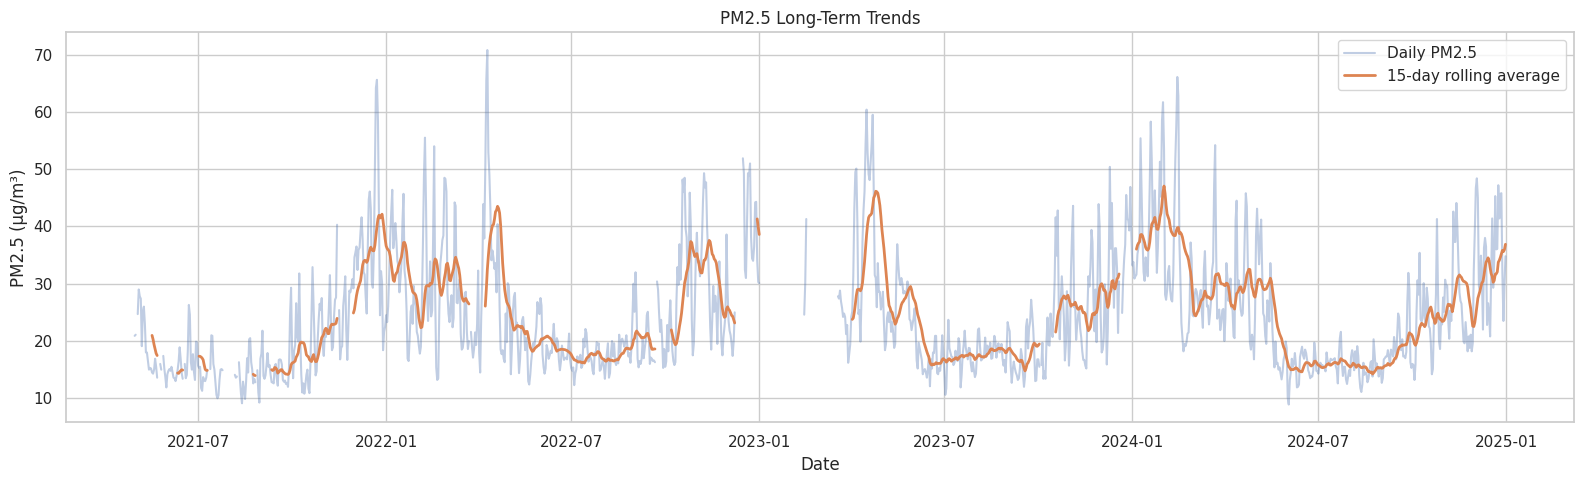

In [ ]:
eda_df["pm25_rolling_15"] = (
    eda_df["pm25"]
    .rolling(window=15, min_periods=15)
    .mean()
)

plt.figure(figsize=(16, 5))

plt.plot(
    eda_df["date"],
    eda_df["pm25"],
    alpha=0.35,
    label="Daily PM2.5"
)

plt.plot(
    eda_df["date"],
    eda_df["pm25_rolling_15"],
    linewidth=2,
    label="15-day rolling average"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 Long-Term Trends")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pm25_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PM2.5 distribution

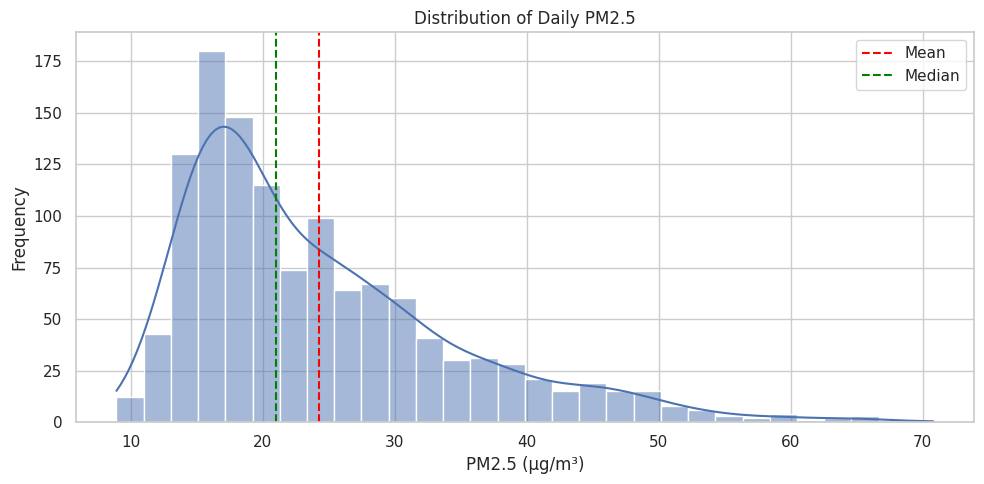

Skewness: 1.2852815569856226


In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df["pm25"].dropna(),
    bins=30,
    kde=True
)

plt.axvline(
    eda_df["pm25"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    eda_df["pm25"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

print("Skewness:", eda_df["pm25"].skew())

Monthly seasonal analysis

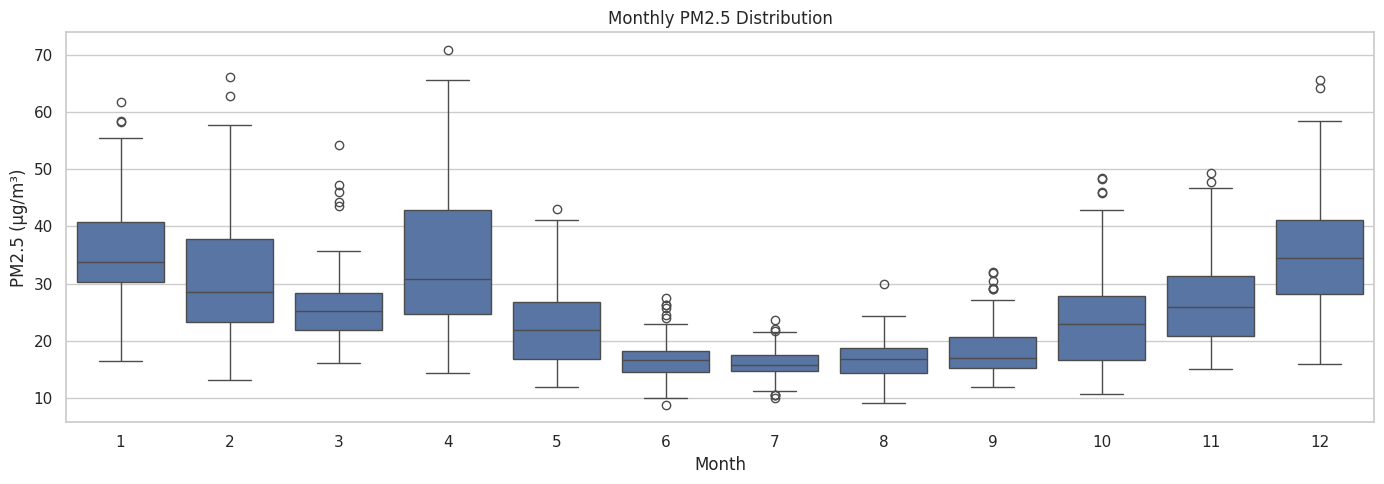

In [ ]:
eda_df["month"] = eda_df["date"].dt.month

plt.figure(figsize=(14, 5))

sns.boxplot(
    data=eda_df,
    x="month",
    y="pm25"
)

plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Monthly PM2.5 Distribution")
plt.tight_layout()
plt.show()

In [ ]:
monthly_stats = (
    eda_df.groupby("month")["pm25"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(monthly_stats)

       count   mean  median    std    min   max
month                                          
1         63  35.62   33.80   9.86  16.50  61.7
2         60  32.13   28.60  12.56  13.20  66.1
3         74  26.38   25.30   7.07  16.20  54.2
4         91  33.45   30.80  12.40  14.50  70.8
5        120  22.50   21.95   6.70  11.90  43.1
6        119  16.81   16.70   3.23   8.91  27.5
7        116  16.11   15.85   2.63  10.00  23.7
8        118  16.59   16.80   3.18   9.13  30.0
9        119  18.24   17.00   4.65  12.00  32.0
10       123  23.73   22.90   8.49  10.80  48.5
11       119  27.41   26.00   7.98  15.20  49.3
12       115  34.69   34.50  10.00  15.90  65.6


Weather correlation analysis

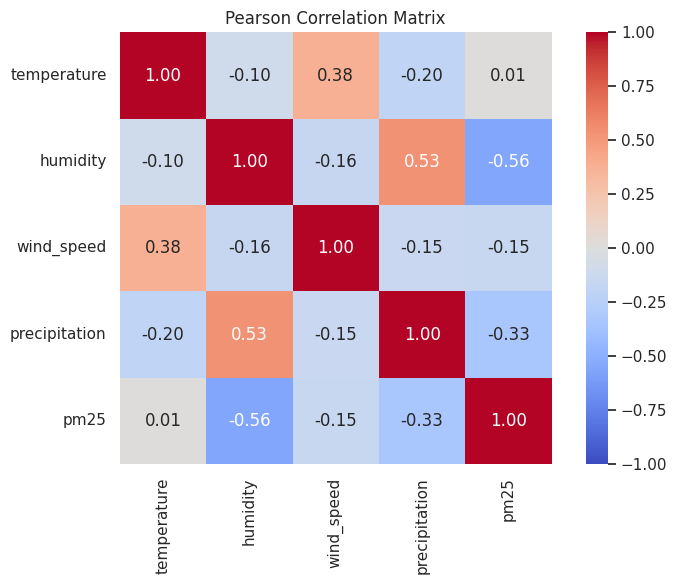

humidity        -0.561438
precipitation   -0.328966
wind_speed      -0.150912
temperature      0.009666
pm25             1.000000
Name: pm25, dtype: float64


In [ ]:
features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation",
    "pm25"
]

correlation = eda_df[features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

print(correlation["pm25"].sort_values())

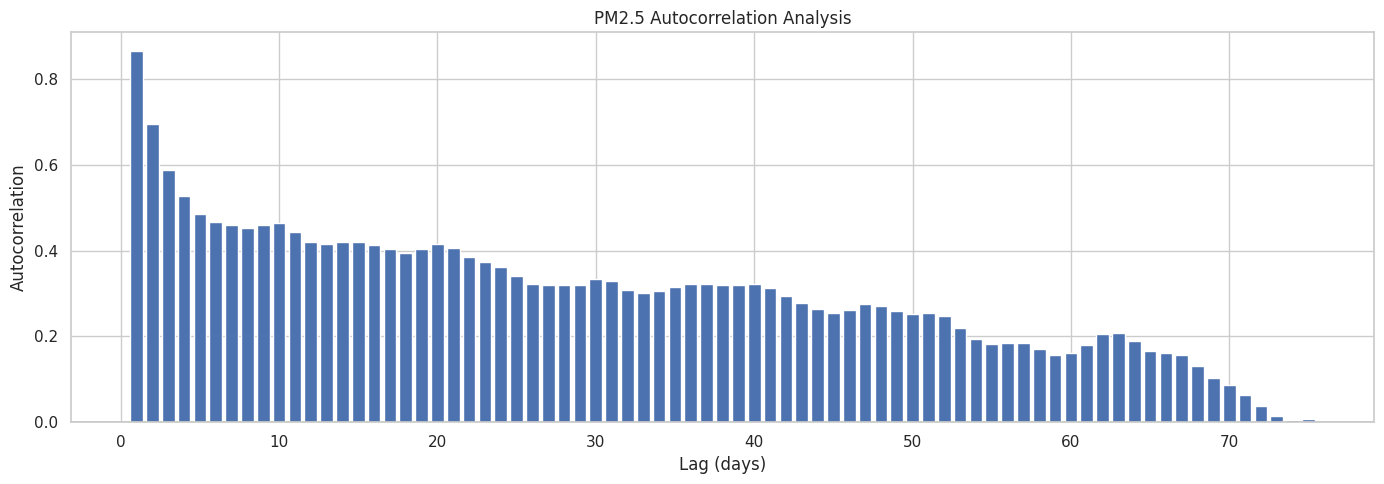

In [ ]:
max_lag = 75

acf_results = []

for lag in range(1, max_lag + 1):

    correlation = eda_df["pm25"].corr(
        eda_df["pm25"].shift(lag)
    )

    acf_results.append({
        "lag": lag,
        "correlation": correlation
    })

acf_df = pd.DataFrame(acf_results)

plt.figure(figsize=(14, 5))

plt.bar(
    acf_df["lag"],
    acf_df["correlation"]
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.title("PM2.5 Autocorrelation Analysis")
plt.tight_layout()
plt.show()

In [ ]:
print(
    acf_df[
        acf_df["lag"].isin(
            [1, 2, 3, 5, 7, 14, 21, 30, 60, 75]
        )
    ].round(3)
)

    lag  correlation
0     1        0.865
1     2        0.695
2     3        0.589
4     5        0.484
6     7        0.459
13   14        0.421
20   21        0.406
29   30        0.335
59   60        0.161
74   75        0.007


Weather yesterday and pm2.5 today correlation

In [ ]:
weather_features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

tomorrow_pm25 = eda_df["pm25"].shift(-1)

for feature in weather_features:

    r = eda_df[feature].corr(tomorrow_pm25)

    print(f"{feature:15}: {r:.3f}")

temperature    : -0.051
humidity       : -0.588
wind_speed     : -0.173
precipitation  : -0.338


# Feature engineering

In [54]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [55]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

df = df.sort_values("date").reset_index(drop=True)

Choosing what window would be suitable

In [56]:
window_results = []

for window in [1, 3, 7, 14, 30]:

    # Check whether every historical input
    # and the target are available
    valid = (
        df["pm25"]
        .notna()
        .rolling(window=window + 1)
        .sum()
        .eq(window + 1)
    )

    train = (
        valid &
        (df["date"] < "2025-01-01")
    )

    val = (
        valid &
        (df["date"] >= "2025-01-01") &
        (df["date"] < "2026-01-01")
    )

    test = (
        valid &
        (df["date"] >= "2026-01-01")
    )

    window_results.append({
        "window_size": window,
        "train_samples": train.sum(),
        "val_samples": val.sum(),
        "test_samples": test.sum(),
        "total_samples": valid.sum()
    })

window_results = pd.DataFrame(window_results)

print(window_results)

   window_size  train_samples  val_samples  test_samples  total_samples
0            1           1219          254           276           1749
1            3           1187          244           274           1705
2            7           1135          224           270           1629
3           14           1045          189           263           1497
4           30            906          141           244           1291


In [57]:
FEATURES = [
    "pm25",
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

TARGET = "pm25"

WINDOW_SIZE = 7

In [58]:
def create_sequences(df, features, target, window_size):

    X = []
    y = []
    dates = []

    for i in range(window_size, len(df)):

        # Historical input
        input_window = df.iloc[i-window_size:i][features]

        # Prediction target
        target_value = df.iloc[i][target]

        # Skip missing historical inputs
        if input_window.isna().any().any():
            continue

        # Skip missing prediction target
        if pd.isna(target_value):
            continue

        X.append(input_window.to_numpy())
        y.append(target_value)
        dates.append(df.iloc[i]["date"])

    return (
        np.array(X),
        np.array(y),
        pd.DatetimeIndex(dates)
    )

In [59]:
X, y, target_dates = create_sequences(
    df,
    FEATURES,
    TARGET,
    WINDOW_SIZE
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target dates shape:", target_dates.shape)

X shape: (1629, 7, 5)
y shape: (1629,)
Target dates shape: (1629,)


In [60]:
print("First input sample:")

print(
    pd.DataFrame(
        X[0],
        columns=FEATURES
    )
)

print("\nTarget PM2.5:", y[0])
print("Target date:", target_dates[0])

First input sample:
   pm25  temperature  humidity  wind_speed  precipitation
0  24.7         29.0      81.0         3.3            1.6
1  29.0         29.5      81.0         4.7           13.9
2  27.8         29.8      79.0         4.6            0.0
3  27.4         27.1      87.0         7.1           10.8
4  19.1         27.5      84.0         7.4            2.8
5  25.2         28.1      85.0         4.5            0.8
6  26.0         28.5      82.0         5.2            1.2

Target PM2.5: 23.0
Target date: 2021-05-10 00:00:00


In [61]:
train_mask = target_dates < "2025-01-01"

val_mask = (
    (target_dates >= "2025-01-01") &
    (target_dates < "2026-01-01")
)

test_mask = target_dates >= "2026-01-01"

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

dates_train = target_dates[train_mask]
dates_val = target_dates[val_mask]
dates_test = target_dates[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1135, 7, 5) (1135,)
Validation: (224, 7, 5) (224,)
Testing: (270, 7, 5) (270,)


In [62]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

In [63]:
output = (
    PROJECT_DIR
    / "data/processed/dataset_window7.npz"
)

np.savez_compressed(
    output,

    X_train=X_train,
    y_train=y_train,

    X_val=X_val,
    y_val=y_val,

    X_test=X_test,
    y_test=y_test,

    dates_train=dates_train.to_numpy(),
    dates_val=dates_val.to_numpy(),
    dates_test=dates_test.to_numpy(),

    features=np.array(FEATURES),
    window_size=WINDOW_SIZE
)

print("Dataset saved:", output)

Dataset saved: /content/drive/MyDrive/PM25_Prediction/data/processed/dataset_window7.npz


In [64]:
with np.load(output) as dataset:

    print("Stored arrays:", dataset.files)

    print("Training:", dataset["X_train"].shape)
    print("Validation:", dataset["X_val"].shape)
    print("Testing:", dataset["X_test"].shape)

    assert np.array_equal(
        dataset["X_train"], X_train
    )

    assert np.array_equal(
        dataset["y_train"], y_train
    )

Stored arrays: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'dates_train', 'dates_val', 'dates_test', 'features', 'window_size']
Training: (1135, 7, 5)
Validation: (224, 7, 5)
Testing: (270, 7, 5)


# Persistence baseline

Base line:
predicting tomorrow's concentration using today's concentration

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

In [65]:
dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()

print("Features:", FEATURES)

Features: ['pm25', 'temperature', 'humidity', 'wind_speed', 'precipitation']


In [66]:
pm25_index = FEATURES.index("pm25")

y_train_pred = X_train[:, -1, pm25_index]
y_val_pred = X_val[:, -1, pm25_index]

print("First 5 predictions:", y_val_pred[:5])
print("First 5 actual values:", y_val[:5])

First 5 predictions: [34.8 35.1 39.4 43.  35.7]
First 5 actual values: [35.1 39.4 43.  35.7 41. ]


In [67]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [68]:
train_results = evaluate_model(
    y_train, y_train_pred
)

val_results = evaluate_model(
    y_val, y_val_pred
)

results = pd.DataFrame(
    [train_results, val_results],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    3.7920  5.4096  0.7263
Validation  4.3737  6.2417  0.8117


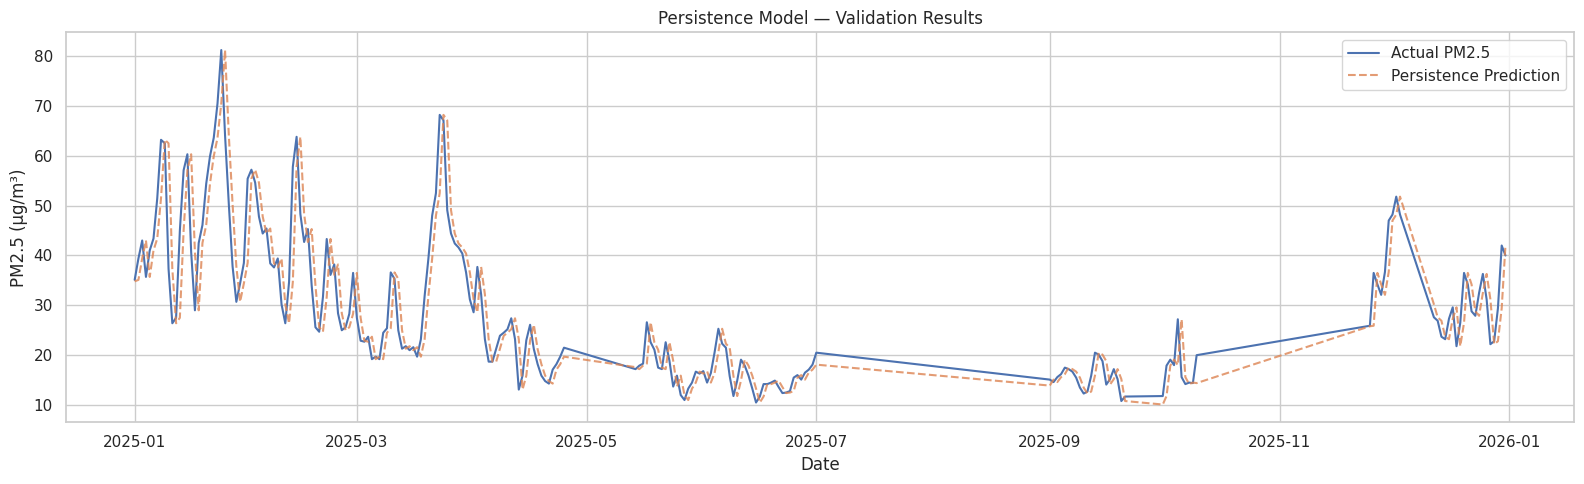

In [69]:
plt.figure(figsize=(16, 5))

plt.plot(
    dates_val,
    y_val,
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    dates_val,
    y_val_pred,
    label="Persistence Prediction",
    linestyle="--",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence Model — Validation Results")
plt.legend()
plt.tight_layout()
plt.show()

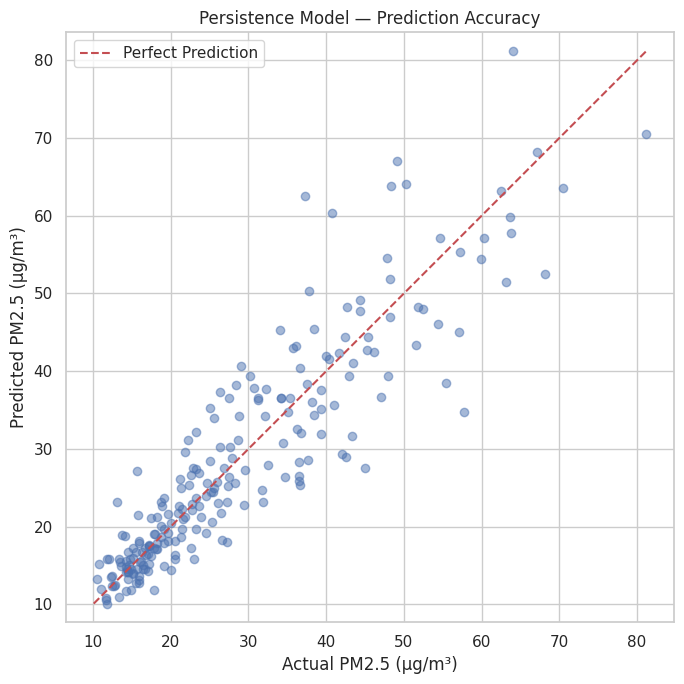

In [70]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    y_val_pred,
    alpha=0.5
)

lower = min(y_val.min(), y_val_pred.min())
upper = max(y_val.max(), y_val_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("Persistence Model — Prediction Accuracy")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

In [71]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])

In [72]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)

Training: (1135, 35)
Validation: (224, 35)
